# 02. 코호트 유지율: 첫 결제월 코호트 × 경과 개월, 구독 유지 vs 활동 유지

**목적**: 첫 결제월 코호트별로 구독이 얼마나 유지되는지 보고, 체험 시작 / 무료 시작 / 유료 시작을 나눠서 비교한다. 구독 유지(결제 기준)가 주 지표이고, 청취 활동 유지는 보조 지표로 본다.

- 데이터: `data/kkbox.duckdb` (사용자 1% 샘플). `sql/04_cohort_retention.sql` 실행 결과 테이블(`cohort_base`, `cohort_user_month`, `cohort_retention`)을 사용한다.
- 정의 요약
  - 코호트: 첫 결제월 (취소 제외 첫 거래 기준), 퍼널 B 코호트(관측 기간 내 가입)만
  - 세그먼트: `trial`(첫 플랜 7일, 체험 추정) / `free_start`(그 외 + 첫 결제 0원) / `paid`(그 외 + 첫 결제 > 0원)
  - 구독 유지: 첫 결제일 + k개월 + 7일 시점에 구독이 유효한가 (`buffer_days = 7`)
  - 활동 유지: 첫 결제일 + k개월부터 한 달 동안 청취 기록(`total_secs > 0`)이 하루라도 있는가
- 이 노트북은 **관찰**까지만 한다. 구독 유지와 청취 활동의 관계, 세그먼트 간 차이는 인과로 해석하지 않는다.
- 실행 위치: `notebooks/` 폴더 (DB 경로가 `../data/kkbox.duckdb`)

In [1]:
import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)
plt.rcParams["font.family"] = "Malgun Gothic"   # Windows 한글 폰트
plt.rcParams["axes.unicode_minus"] = False

DB_PATH = "../data/kkbox.duckdb"
con = duckdb.connect(DB_PATH, read_only=True)


def q(sql):
    return con.sql(sql).df()

## 0. 전제 확인

04를 실행하지 않았거나 예전 버전(`buffer_days` 열이 없는 버전)이면 여기서 멈춘다.

In [2]:
need = ["cohort_base", "cohort_user_month", "cohort_retention", "user_logs_sample", "params"]
existing = set(q("SHOW TABLES")["name"])
missing = [t for t in need if t not in existing]
assert not missing, f"없는 테이블: {missing}. sql/04_cohort_retention.sql을 먼저 실행하세요."

cols = set(q("DESCRIBE cohort_user_month")["column_name"])
assert "buffer_days" in cols, "cohort_user_month에 buffer_days가 없음: 04 최신 버전을 다시 실행하세요."

print("데이터 종료일:", q("SELECT data_end FROM params").iloc[0, 0])
q('''
SELECT segment, COUNT(*) AS users,
       MIN(cohort_month) AS first_cohort, MAX(cohort_month) AS last_cohort
FROM cohort_base
GROUP BY segment
ORDER BY segment
''')

데이터 종료일: 2017-03-31 00:00:00


,segment,users,first_cohort,last_cohort
0,free_start,767,2015-01-01,2017-03-01
1,paid,6100,2015-01-01,2017-03-01
2,trial,2230,2015-03-01,2017-01-01


## 1. 코호트 × 경과 개월 유지율 히트맵

- 세로축은 첫 결제월 코호트, 가로축은 첫 결제 후 경과 개월(`month_k`)이다. 값은 그 시점에 구독이 유효한 사용자의 비율(%)이다.
- 해당 칸의 인원이 30명 미만이면 가린다. 코호트 규모가 작으면 비율이 크게 흔들리기 때문이다. 관측 기간 밖(데이터 종료일을 넘는 시점)인 칸은 비어 있다.
- `buffer_days = 7`만 사용한다. 체험(trial)은 값이 낮아서 색상 범위를 0~20%로 따로 잡았다. 세그먼트 간 색을 그대로 비교하면 안 된다.

In [3]:
MIN_N = 30
SEGMENTS = ["paid", "free_start", "trial"]
SEG_LABEL = {
    "paid": "유료 시작 (paid)",
    "free_start": "무료 시작 (free_start)",
    "trial": "체험 시작 (trial, 7일 플랜)",
}

ret = q('''
SELECT cohort_month, segment, month_k, users, retained_users, retention_pct
FROM cohort_retention
WHERE buffer_days = 7
ORDER BY segment, cohort_month, month_k
''')
ret["cohort_month"] = pd.to_datetime(ret["cohort_month"])
ret.head()

,cohort_month,segment,month_k,users,retained_users,retention_pct
0,2015-01-01,free_start,0,22,22,100.00
1,2015-01-01,free_start,1,22,22,100.00
2,2015-01-01,free_start,2,22,19,86.36
3,2015-01-01,free_start,3,22,18,81.82
4,2015-01-01,free_start,4,22,16,72.73


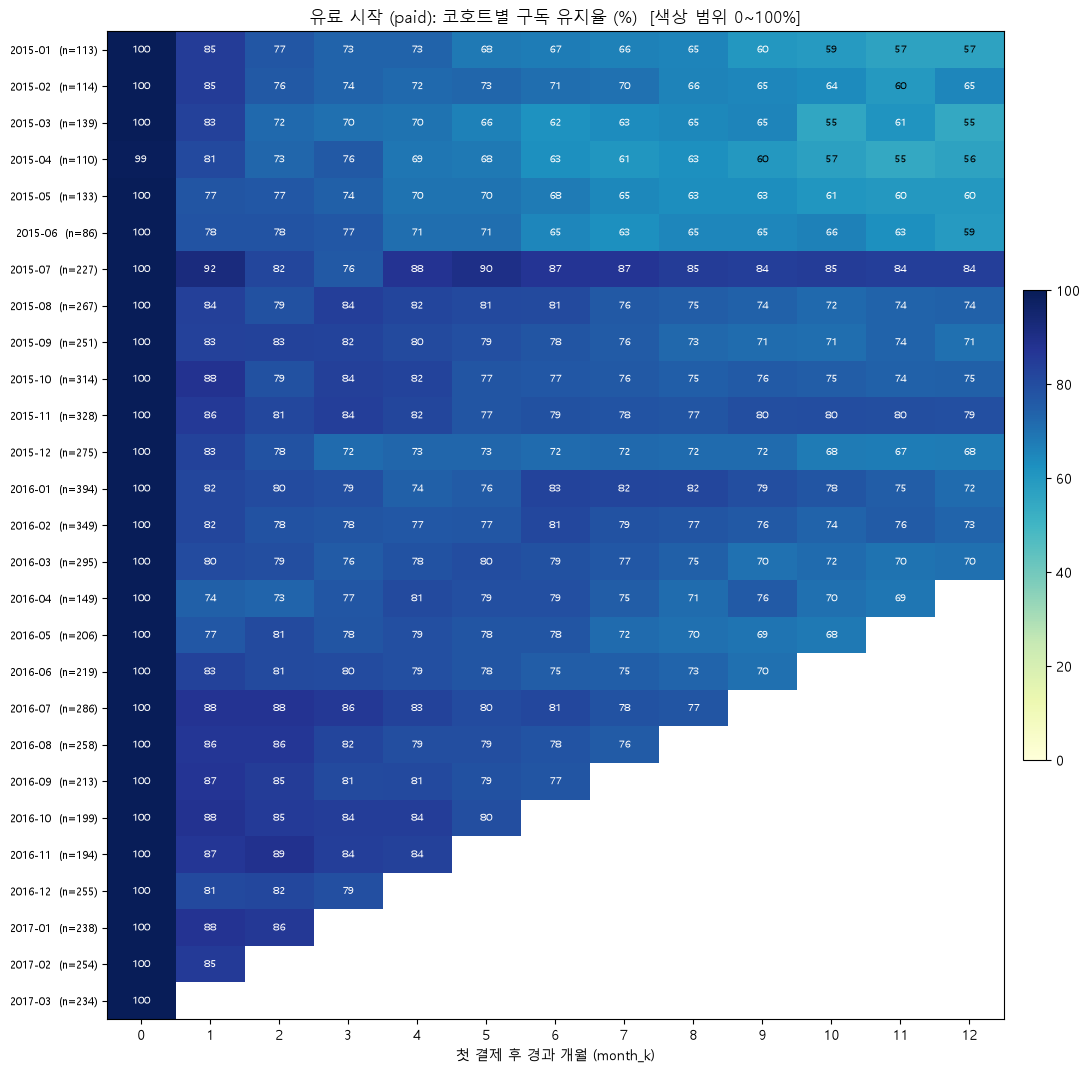

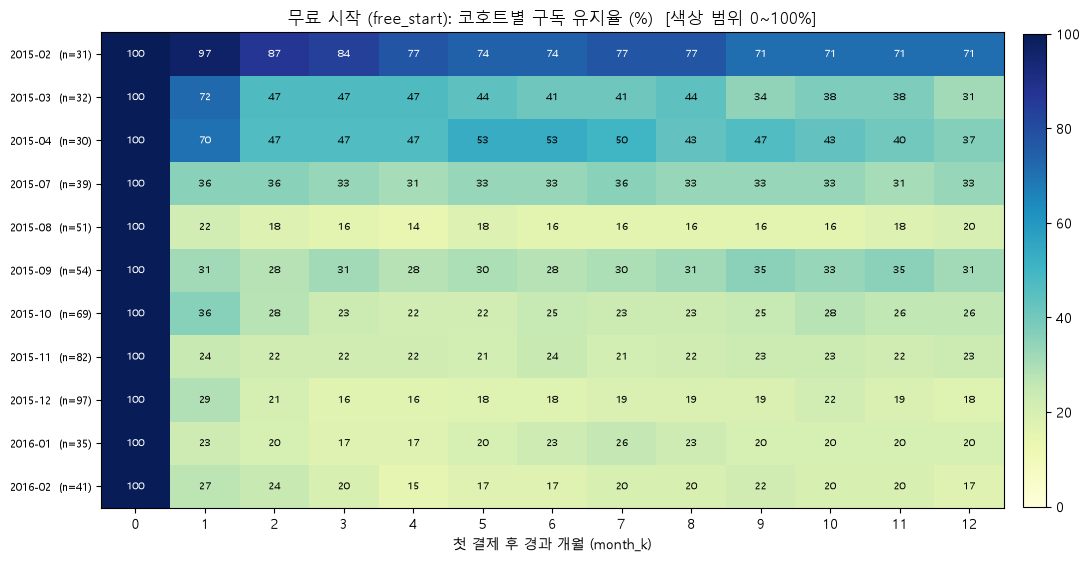

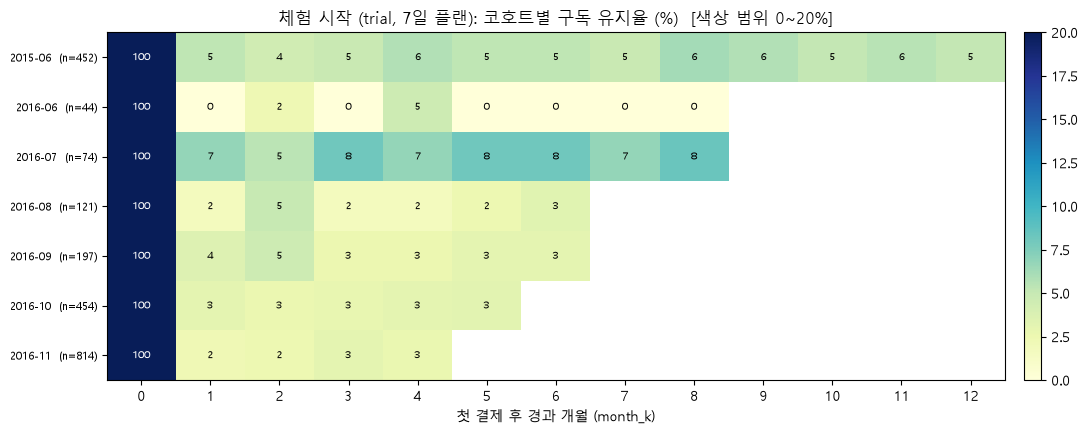

In [4]:
def draw_heatmap(seg, vmax):
    d = ret[ret["segment"] == seg]
    size0 = d[d["month_k"] == 0].set_index("cohort_month")["users"]
    keep = size0[size0 >= MIN_N].index              # 코호트 규모가 30명 이상인 월만 표시
    d = d[d["cohort_month"].isin(keep)]

    fig, ax = plt.subplots(figsize=(11, 0.32 * max(len(keep), 3) + 2.2))
    if d.empty:
        ax.text(0.5, 0.5, f"코호트 규모 {MIN_N}명 이상인 월이 없음", ha="center", va="center")
        ax.set_axis_off()
        ax.set_title(SEG_LABEL[seg])
        return fig

    pct = d.pivot(index="cohort_month", columns="month_k", values="retention_pct").reindex(columns=range(13))
    n = d.pivot(index="cohort_month", columns="month_k", values="users").reindex(columns=range(13))
    pct = pct.where(n >= MIN_N)                     # 칸별 인원이 30명 미만이면 가림

    im = ax.imshow(np.ma.masked_invalid(pct.values), aspect="auto", cmap="YlGnBu", vmin=0, vmax=vmax)
    ax.set_xticks(range(13))
    ax.set_xticklabels(range(13))
    ax.set_yticks(range(len(pct)))
    ax.set_yticklabels([f"{m:%Y-%m}  (n={int(size0[m]):,})" for m in pct.index], fontsize=8)
    ax.set_xlabel("첫 결제 후 경과 개월 (month_k)")
    ax.set_title(f"{SEG_LABEL[seg]}: 코호트별 구독 유지율 (%)  [색상 범위 0~{vmax}%]")
    for i in range(pct.shape[0]):
        for j in range(pct.shape[1]):
            v = pct.values[i, j]
            if not np.isnan(v):
                ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=7,
                        color="white" if v > vmax * 0.6 else "black")
    fig.colorbar(im, ax=ax, fraction=0.025, pad=0.02)
    fig.tight_layout()
    return fig


for seg, vmax in [("paid", 100), ("free_start", 100), ("trial", 20)]:
    draw_heatmap(seg, vmax)
    plt.show()

## 2. 유지 곡선: 합산 곡선과 고정 코호트 곡선

`month_k`가 커질수록 아직 관측되지 않은 최근 코호트가 빠지므로, 전체를 합산한 곡선은 월별로 **구성이 바뀐다**. 그래서 곡선의 모양이 실제 변화인지 구성 변화인지 구분하려고 두 가지를 같이 그린다.

- 합산(관측 가능한 전체): `month_k`마다 그 시점이 관측되는 모든 코호트를 합친다. 구성이 바뀔 수 있다.
- 고정 코호트: 12개월(또는 6개월)까지 **전원이 관측되는 코호트만** 고정해서 합친다. 구성이 바뀌지 않는다.

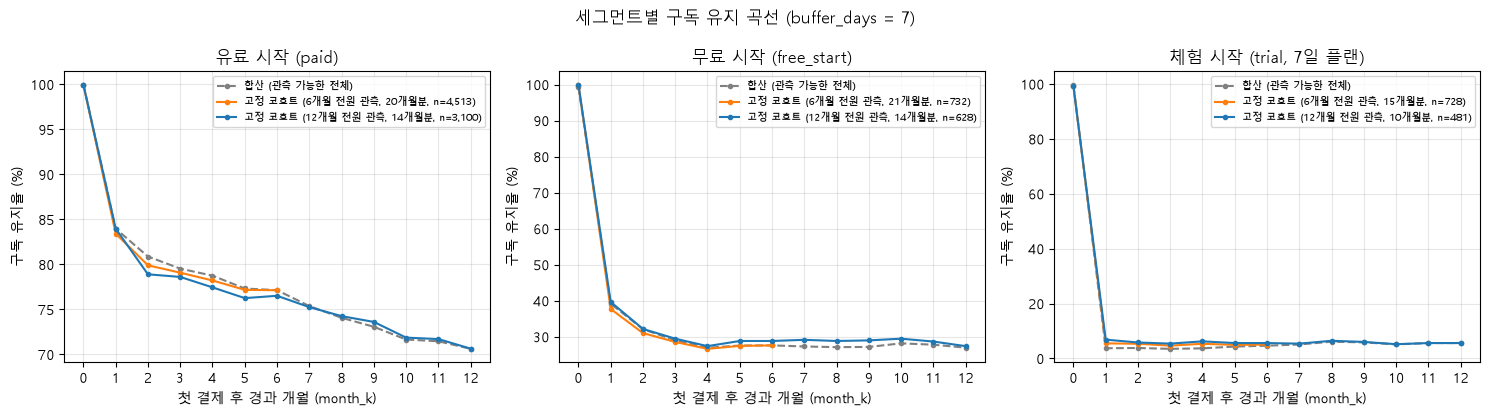

,segment,horizon,cohorts,users
0,paid,6,20,4513
1,paid,12,14,3100
2,free_start,6,21,732
3,free_start,12,14,628
4,trial,6,15,728
5,trial,12,10,481


In [5]:
def fixed_cohorts(d, horizon):
    '''month_k = 0..horizon 전 구간에서 코호트 전원(month_k=0 인원)이 관측되는 코호트 목록'''
    size0 = d[d["month_k"] == 0].set_index("cohort_month")["users"]
    d = d.assign(full=d["users"] == d["cohort_month"].map(size0))
    g = (d[d["month_k"] <= horizon]
         .groupby("cohort_month")
         .agg(n_k=("month_k", "size"), n_full=("full", "sum")))
    return g[(g["n_k"] == horizon + 1) & (g["n_full"] == horizon + 1)].index


def pooled_curve(d):
    g = d.groupby("month_k")[["retained_users", "users"]].sum()
    return 100.0 * g["retained_users"] / g["users"]


fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), sharey=False)
rows = []
for ax, seg in zip(axes, SEGMENTS):
    d = ret[ret["segment"] == seg]
    ax.plot(pooled_curve(d), color="gray", linestyle="--", marker="o", ms=3,
            label="합산 (관측 가능한 전체)")
    for horizon, color in [(6, "tab:orange"), (12, "tab:blue")]:
        keep = fixed_cohorts(d, horizon)
        if len(keep) == 0:
            rows.append({"segment": seg, "horizon": horizon, "cohorts": 0, "users": 0})
            continue
        sub = d[d["cohort_month"].isin(keep) & (d["month_k"] <= horizon)]
        n_users = int(d[(d["month_k"] == 0) & d["cohort_month"].isin(keep)]["users"].sum())
        ax.plot(pooled_curve(sub), color=color, marker="o", ms=3,
                label=f"고정 코호트 ({horizon}개월 전원 관측, {len(keep)}개월분, n={n_users:,})")
        rows.append({"segment": seg, "horizon": horizon, "cohorts": len(keep), "users": n_users})
    ax.set_title(SEG_LABEL[seg])
    ax.set_xlabel("첫 결제 후 경과 개월 (month_k)")
    ax.set_ylabel("구독 유지율 (%)")
    ax.set_xticks(range(13))
    ax.grid(alpha=0.3)
    ax.legend(fontsize=7, loc="upper right")
fig.suptitle("세그먼트별 구독 유지 곡선 (buffer_days = 7)")
fig.tight_layout()
plt.show()

pd.DataFrame(rows)

## 3. 구독 유지 vs 활동 유지 (활동 정의 A)

- **활동 유지**: 첫 결제일 + k개월부터 한 달(`[d0 + k개월, d0 + (k+1)개월)`) 동안 청취 기록이 하루라도 있으면 활동으로 본다. 청취 기록은 `total_secs > 0`인 로그 행이다(02에서 음수 청취 시간을 제외한 것과 같은 기준).
- 구독 유지와 같은 모집단, 같은 `buffer_days = 7`을 쓴다. 활동 윈도우의 끝이 관측 가능한 날짜(데이터 종료일과 로그 종료일 중 빠른 날) 이내인 (사용자, month_k)만 비교한다. 그래서 여기 나오는 구독 유지율은 04의 표와 마지막 월 쪽에서 조금 다를 수 있다.
- 청취 로그가 아예 없는 사용자는 모든 달에 비활동으로 잡힌다. 아래에서 그 비율을 따로 확인한다.
- 구독 유지와 활동은 시점의 기준이 조금 다르다(구독은 한 시점, 활동은 한 달 구간). 만료 직후 며칠만 들은 경우처럼 경계에서 "구독 미유지인데 활동"이 생길 수 있다.

In [6]:
log_range = q("SELECT MIN(log_date) AS log_start, MAX(log_date) AS log_end FROM user_logs_sample")
data_end = pd.Timestamp(q("SELECT data_end FROM params").iloc[0, 0])
log_start = pd.Timestamp(log_range["log_start"].iloc[0])
log_end = pd.Timestamp(log_range["log_end"].iloc[0])
obs_end = min(data_end, log_end)
print(f"로그 기간: {log_start:%Y-%m-%d} ~ {log_end:%Y-%m-%d}")
print(f"데이터 종료일: {data_end:%Y-%m-%d}")
print(f"활동 비교에 쓰는 관측 종료일: {obs_end:%Y-%m-%d}")
if log_end < data_end:
    print("주의: 로그가 데이터 종료일보다 일찍 끝남. 그 이후 윈도우는 비교에서 제외됨.")
if pd.Timestamp(q("SELECT MIN(d0) AS d FROM cohort_base")["d"].iloc[0]) < log_start:
    print("주의: 로그 시작일보다 이른 첫 결제 코호트가 있음. 그 윈도우는 제외됨.")

로그 기간: 2015-01-01 ~ 2017-03-31
데이터 종료일: 2017-03-31
활동 비교에 쓰는 관측 종료일: 2017-03-31


In [7]:
act = q(f'''
WITH grid AS (
    SELECT c.msno, c.segment, c.cohort_month, c.month_k, c.retained,
           (b.d0 + to_months(CAST(c.month_k AS INTEGER)))::DATE     AS win_start,
           (b.d0 + to_months(CAST(c.month_k AS INTEGER) + 1))::DATE AS win_end
    FROM cohort_user_month c
    JOIN cohort_base b USING (msno)
    WHERE c.buffer_days = 7
)
SELECT g.segment, g.cohort_month, g.month_k, g.msno, g.retained,
       EXISTS (SELECT 1
               FROM user_logs_sample l
               WHERE l.msno = g.msno
                 AND l.total_secs > 0
                 AND l.log_date >= g.win_start
                 AND l.log_date <  g.win_end) AS active
FROM grid g
WHERE g.win_end <= DATE '{obs_end:%Y-%m-%d}'
  AND g.win_start >= DATE '{log_start:%Y-%m-%d}'
''')
print(f"(사용자, month_k) 행 수: {len(act):,}")
act.groupby("segment")["msno"].nunique().rename("users")

(사용자, month_k) 행 수: 82,408


segment
free_start     758
paid          5866
trial         2230
Name: users, dtype: int64

In [8]:
by_seg_k = (act.groupby(["segment", "month_k"])
            .agg(users=("msno", "size"),
                 sub_retained=("retained", "mean"),
                 active=("active", "mean"))
            .reset_index())

active_among_retained = (act[act["retained"]].groupby(["segment", "month_k"])["active"].mean()
                         .rename("active_among_retained"))
active_among_not_retained = (act[~act["retained"]].groupby(["segment", "month_k"])["active"].mean()
                             .rename("active_among_not_retained"))

tab = (by_seg_k.set_index(["segment", "month_k"])
       .join(active_among_retained)
       .join(active_among_not_retained)
       .reset_index())
for c in ["sub_retained", "active", "active_among_retained", "active_among_not_retained"]:
    tab[c] = (100 * tab[c]).round(2)
tab

,segment,month_k,users,sub_retained,active,active_among_retained,active_among_not_retained
0,free_start,0,758,99.34,91.03,90.97,100.00
1,free_start,1,751,38.75,40.88,74.91,19.35
2,free_start,2,743,31.63,28.94,75.74,7.28
3,free_start,3,736,28.80,25.95,81.13,3.63
4,free_start,4,733,26.74,25.10,83.16,3.91
5,free_start,5,732,27.46,25.14,81.09,3.95
6,free_start,6,731,27.50,24.76,81.09,3.40
7,free_start,7,725,27.45,24.55,81.91,2.85
8,free_start,8,716,27.09,24.44,80.93,3.45
9,free_start,9,698,27.22,25.21,83.16,3.54


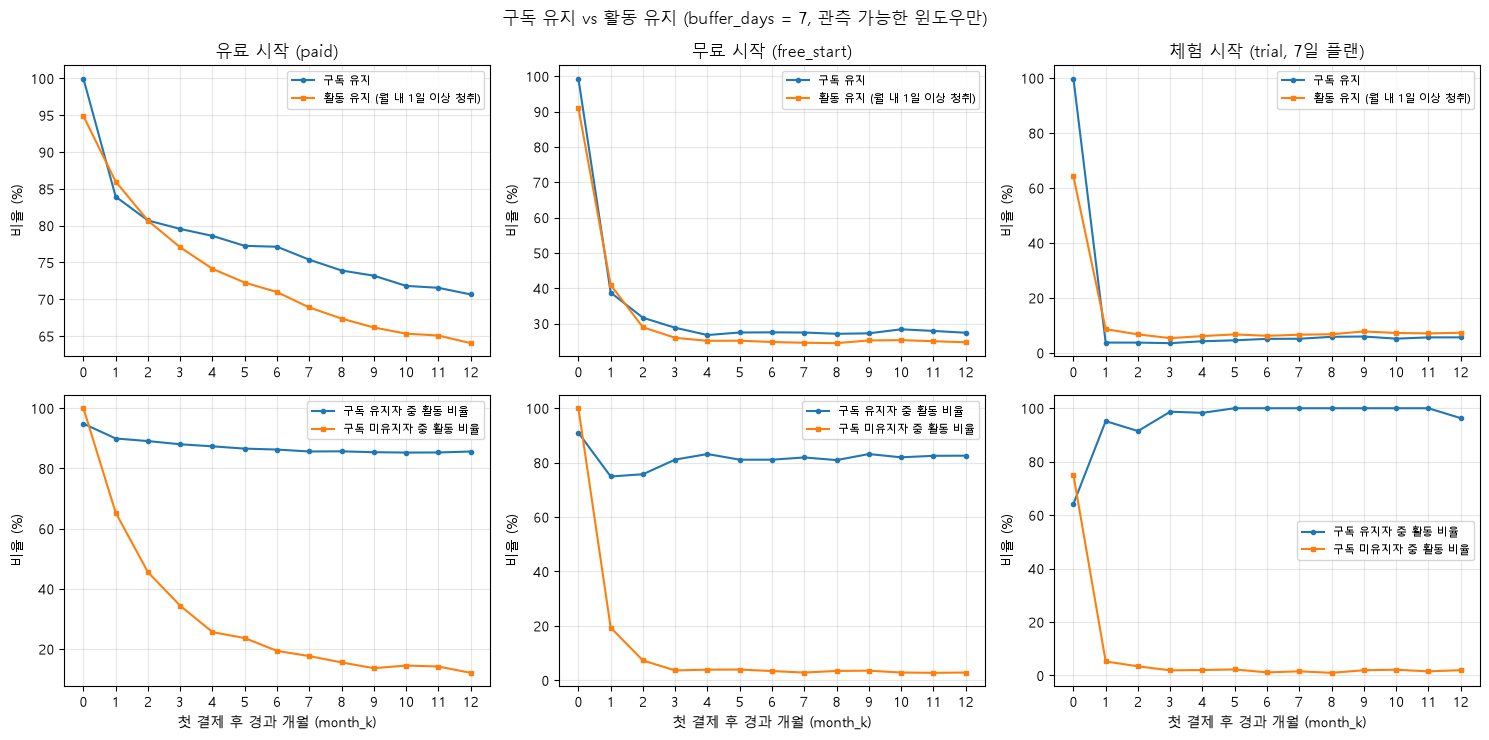

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7.5))
for j, seg in enumerate(SEGMENTS):
    t = tab[tab["segment"] == seg]
    ax = axes[0, j]
    ax.plot(t["month_k"], t["sub_retained"], marker="o", ms=3, label="구독 유지")
    ax.plot(t["month_k"], t["active"], marker="s", ms=3, label="활동 유지 (월 내 1일 이상 청취)")
    ax.set_title(SEG_LABEL[seg])
    ax.set_ylabel("비율 (%)")
    ax.set_xticks(range(13))
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)

    ax = axes[1, j]
    ax.plot(t["month_k"], t["active_among_retained"], marker="o", ms=3, label="구독 유지자 중 활동 비율")
    ax.plot(t["month_k"], t["active_among_not_retained"], marker="s", ms=3, label="구독 미유지자 중 활동 비율")
    ax.set_xlabel("첫 결제 후 경과 개월 (month_k)")
    ax.set_ylabel("비율 (%)")
    ax.set_xticks(range(13))
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
fig.suptitle("구독 유지 vs 활동 유지 (buffer_days = 7, 관측 가능한 윈도우만)")
fig.tight_layout()
plt.show()

### 청취 로그가 아예 없는 사용자

로그가 없는 사용자는 모든 달에 비활동으로 잡혀서 활동 유지율을 낮춘다. 세그먼트별 비율을 확인해 둔다.

In [10]:
q('''
SELECT b.segment,
       COUNT(*) AS users,
       COUNT(*) FILTER (WHERE NOT EXISTS (SELECT 1 FROM user_logs_sample l WHERE l.msno = b.msno)) AS no_log_rows,
       ROUND(100.0 * COUNT(*) FILTER (WHERE NOT EXISTS (SELECT 1 FROM user_logs_sample l WHERE l.msno = b.msno))
             / COUNT(*), 2) AS no_log_pct
FROM cohort_base b
GROUP BY b.segment
ORDER BY b.segment
''')

,segment,users,no_log_rows,no_log_pct
0,free_start,767,8,1.04
1,paid,6100,46,0.75
2,trial,2230,97,4.35


## 4. 정리와 한계

**04 결과에서 확인한 것 (buffer_days = 7, 합산 곡선)**

- paid는 1개월차 83.97%에서 12개월차 70.62%로 완만하게 내려간다.
- free_start는 1개월차 39.18%에서 4개월차 이후 약 27%로 내려간 뒤 거의 평평하다.
- trial은 월별 3~6% 안팎이다. 다만 합산 곡선의 월별 움직임에는 코호트 구성 변화가 섞여 있다(`month_k` 4에서 5로 갈 때 분모가 2,086명에서 1,108명으로 줄어듦). 그래서 2절의 고정 코호트 곡선을 같이 본다.
- buffer 민감도: paid 1개월차는 buffer 0일 81.21%, 14일 85.69%로 달라진다. 3개월차 이후에는 buffer 0~7일의 차이가 0.5%p 안쪽이고, 14일은 오히려 낮다.

히트맵(1절)과 활동 유지(3절)에 대한 해석은 실행 결과를 확인한 뒤 이 셀에 추가한다.

**한계**

- 구독 유지는 한 시점에 구독이 유효한지를 보는 지표라서, 퍼널의 1차 갱신률(만료 후 30일 안에 재결제하면 갱신)과 다른 지표다. 두 숫자를 직접 비교하면 안 된다.
- `buffer_days = 7`은 달력 월 기준 만료일(첫 결제일 + 31~33일)을 흡수하려고 정했다. 값을 바꾸면 1개월차 수치가 달라진다(민감도는 위 참고).
- `free_start`는 첫 결제금액이 0원인 시작자다. 쿠폰·프로모션 시작으로 추정하지만, 데이터에 사유 정보가 없어서 확정할 수 없다.
- `trial`은 첫 플랜이 7일인 사용자다(체험 추정). 첫 결제금액이 0원이 아닌 7일 플랜이 섞여 있는지는 확인하지 않았다.
- 코호트 규모 차이가 크다. 체험 시작자는 2015-06, 2016-10, 2016-11 코호트에 몰려 있어서, 이 달의 행동이 trial 전체 곡선을 좌우한다.
- 활동 유지는 청취 로그가 있는 날만 본다. 로그가 없는 사용자와 로그 기간 밖의 윈도우는 비교에서 빠지거나 비활동으로 잡힌다.
- 모두 관찰 데이터이므로, 세그먼트 간 차이나 구독·활동의 관계를 인과로 읽지 않는다.